In [9]:
'''
task: FOL classification based on graph data from AST
model: graphormer
dataset: FOLIO
evaluation: supervised fine-tuning
'''
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [10]:
# load FOLIO dataset
import pandas as pd

fol_train = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/folio/data/folio_ast_train.csv")
fol_test = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/folio/data/folio_ast_test.csv")
fol_valid = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/folio/data/folio_ast_val.csv")

In [11]:
# logic to generate graph from AST
import json
import matplotlib.pyplot as plt
import networkx as nx

def extract_text(node):
    """Recursively processes specific sub-tokens to rebuild logic strings."""
    pieces = []
    if "text" in node:
        pieces.append(node["text"])
    if "children" in node:
        for child in node["children"]:
            pieces.extend(extract_text(child))
    return "".join(pieces)

def clean_syntax(text):
    """Formats string operations into formal math notation markers."""
    return (text.strip()
            .replace("forall", "∀ ")
            .replace("implies", " → ")
            .replace("and", " ∧ ")
            .replace("not", " ¬ ")
            .replace("()", ""))

def ast_to_syllogism_graph(ast_dict):
  """Transforms an AST into a directed NetworkX graph where all nodes

  sharing the same name/label (regardless of type, e.g., symbol 'x' and term 'x')
  are merged into a single unique node, accumulating all incoming and
  outgoing edges.
  """
  G = nx.DiGraph()

  # 1. Add Root Node
  root_node = "Syllogism"
  G.add_node(root_node, label="Syllogism", node_type="root")

  # Helper to safely locate statements in the AST structure
  def find_statements(node):
    stats = []
    if not isinstance(node, dict):
      return stats

    if node.get("type") == "stat":
      stats.append(node)

    for child in node.get("children", []):
      stats.extend(find_statements(child))

    return stats

  statements = find_statements(ast_dict)
  if not statements:
    return G

  premises = statements[:-1]
  conclusion = statements[-1]

  # Helper to split a term node's contents by commas (e.g., x,y or tecmo,japan)
  def extract_sub_terms_from_node(node):
    if not isinstance(node, dict):
      return []

    sub_terms = []
    current_letters = []
    for child in node.get("children", []):
      child_type = child.get("type")
      if child_type == "COMMA":
        if current_letters:
          sub_terms.append("".join(current_letters))
          current_letters = []
      elif child_type == "LETTER" and "text" in child:
        current_letters.append(child["text"])
      else:
        nested = extract_sub_terms_from_node(child)
        if nested:
          sub_terms.extend(nested)
    if current_letters:
      sub_terms.append("".join(current_letters))

    if not sub_terms and "text" in node:
      sub_terms.append(node["text"])

    return sub_terms

  # Helper to find text inside simple nodes like quantifier, keyword, symbol
  def get_node_text(node):
    if not isinstance(node, dict):
      return ""
    if "text" in node:
      return node["text"]
    for child in node.get("children", []):
      res = get_node_text(child)
      if res:
        return res
    return ""

  def collect_keywords(node, keywords):
    if not isinstance(node, dict):
      return
    if node.get("type") == "keyword":
      kw_text = get_node_text(node)
      if kw_text and kw_text not in keywords:
        keywords.append(kw_text)
    for child in node.get("children", []):
      collect_keywords(child, keywords)

  def find_atomic_propositions(node):
    aps = []
    if not isinstance(node, dict):
      return aps
    if node.get("type") == "atomicproposition":
      aps.append(node)
    for child in node.get("children", []):
      aps.extend(find_atomic_propositions(child))
    return aps

  # Helper to ensure unique nodes by label name (merges different types with same name)
  def add_merged_node(label, node_type):
    if not G.has_node(label):
      G.add_node(label, label=label, node_type=node_type)
    else:
      # Optional: update node_type to reflect multiple roles if needed
      existing_type = G.nodes[label].get("node_type", "")
      if node_type not in existing_type:
        G.nodes[label]["node_type"] = f"{existing_type},{node_type}"
    return label

  # Process a single statement (Premise or Conclusion)
  def process_statement(stat_node, parent_graph_node):
    quantifier_label = None
    symbol_label = None

    def find_quantifier_symbol(node):
      nonlocal quantifier_label, symbol_label
      if not isinstance(node, dict):
        return
      ntype = node.get("type")
      if ntype == "quantifier":
        q_text = get_node_text(node)
        if q_text:
          quantifier_label = add_merged_node(q_text, "quantifier")
          G.add_edge(parent_graph_node, quantifier_label)
      elif ntype == "symbol" and quantifier_label:
        s_text = get_node_text(node)
        if s_text:
          symbol_label = add_merged_node(s_text, "symbol")
          G.add_edge(quantifier_label, symbol_label)

      for child in node.get("children", []):
        find_quantifier_symbol(child)

    find_quantifier_symbol(stat_node)

    # Process Atomic Propositions (Predicate -> Argument Term Edges)
    aps = find_atomic_propositions(stat_node)
    statement_terms = set()

    for ap in aps:
      term_children = [
          c for c in ap.get("children", []) if c.get("type") == "term"
      ]
      ap_terms = []
      for tc in term_children:
        sub = extract_sub_terms_from_node(tc)
        ap_terms.extend(sub)

      if ap_terms:
        predicate_text = ap_terms[0]
        pred_label = add_merged_node(predicate_text, "term")
        G.add_edge(parent_graph_node, pred_label)
        statement_terms.add(predicate_text)

        for arg_text in ap_terms[1:]:
          arg_label = add_merged_node(arg_text, "term")
          G.add_edge(parent_graph_node, arg_label)
          statement_terms.add(arg_text)

          # Directed edge from predicate to argument term
          G.add_edge(pred_label, arg_label)

    # Fallback for any standalone terms not caught in atomic propositions
    def find_all_terms(node):
      if not isinstance(node, dict):
        return
      if node.get("type") == "term":
        for t in extract_sub_terms_from_node(node):
          if t not in statement_terms:
            t_label = add_merged_node(t, "term")
            G.add_edge(parent_graph_node, t_label)
            statement_terms.add(t)
      for child in node.get("children", []):
        find_all_terms(child)

    find_all_terms(stat_node)

    # Keywords -> Connect keyword to all terms in the statement
    keywords = []
    collect_keywords(stat_node, keywords)

    for kw in keywords:
      kw_label = add_merged_node(kw, "keyword")
      G.add_edge(parent_graph_node, kw_label)

      # Connect keyword to all terms present in this statement
      for t in statement_terms:
        G.add_edge(kw_label, t)

  # 2. Process Premises
  for idx, premise in enumerate(premises):
    premise_name = f"Premise_{idx + 1}"
    add_merged_node(premise_name, "premise")
    G.add_edge(root_node, premise_name)
    process_statement(premise, premise_name)

  # 3. Process Conclusion
  conclusion_name = "Conclusion"
  add_merged_node(conclusion_name, "conclusion")
  G.add_edge(root_node, conclusion_name)
  process_statement(conclusion, conclusion_name)

  return G

In [13]:
# generate graphs from PFOLIO train dataset
train_graph_list = [] # graph transformation of each syllogism
train_label_list = [] # label for each graph (syllogism)
for idx, row in fol_train.iterrows():
    premises_ast = row["Premises - CLIF"]
    conclusion_ast = row["Conclusions - CLIF"]
    # replace single quotes with double quotes to make it valid JSON
    premises_ast = premises_ast.replace("'", '"')
    conclusion_ast = conclusion_ast.replace("'", '"')
    # add conlusion as a child to premises dict
    premises_ast = json.loads(premises_ast)
    conclusion_ast = json.loads(conclusion_ast)
    premises_ast["children"].append(conclusion_ast["children"][0]["children"][0])
    premises_ast = premises_ast["children"][0]  # get the first child of premises as the root of the AST
    ast_data = premises_ast
    # generate graph from AST
    ast_graph = ast_to_syllogism_graph(ast_data)
    train_graph_list.append(ast_graph)
    train_label_list.append(row["label"])

print("*** Train data graph dataset generation complete ***")

# generate graphs from PFOLIO test dataset
test_graph_list = [] # graph transformation of each syllogism
test_label_list = [] # label for each graph (syllogism)
for idx, row in fol_test.iterrows():
    premises_ast = row["Premises - CLIF"]
    conclusion_ast = row["Conclusions - CLIF"]
    # replace single quotes with double quotes to make it valid JSON
    premises_ast = premises_ast.replace("'", '"')
    conclusion_ast = conclusion_ast.replace("'", '"')
    # add conlusion as a child to premises dict
    premises_ast = json.loads(premises_ast)
    conclusion_ast = json.loads(conclusion_ast)
    premises_ast["children"].append(conclusion_ast["children"][0]["children"][0])
    premises_ast = premises_ast["children"][0]  # get the first child of premises as the root of the AST
    ast_data = premises_ast
    # generate graph from AST
    ast_graph = ast_to_syllogism_graph(ast_data)
    test_graph_list.append(ast_graph)
    test_label_list.append(row["label"])

print("*** Test data graph dataset generation complete ***")

# generate graphs from PFOLIO val dataset
val_graph_list = [] # graph transformation of each syllogism
val_label_list = [] # label for each graph (syllogism)
for idx, row in fol_valid.iterrows():
    premises_ast = row["Premises - CLIF"]
    conclusion_ast = row["Conclusions - CLIF"]
    # replace single quotes with double quotes to make it valid JSON
    premises_ast = premises_ast.replace("'", '"')
    conclusion_ast = conclusion_ast.replace("'", '"')
    # add conlusion as a child to premises dict
    premises_ast = json.loads(premises_ast)
    conclusion_ast = json.loads(conclusion_ast)
    premises_ast["children"].append(conclusion_ast["children"][0]["children"][0])
    premises_ast = premises_ast["children"][0]  # get the first child of premises as the root of the AST
    ast_data = premises_ast
    # generate graph from AST
    ast_graph = ast_to_syllogism_graph(ast_data)
    val_graph_list.append(ast_graph)
    val_label_list.append(row["label"])

print("*** Val data graph dataset generation complete ***")

*** Train data graph dataset generation complete ***
*** Test data graph dataset generation complete ***
*** Val data graph dataset generation complete ***


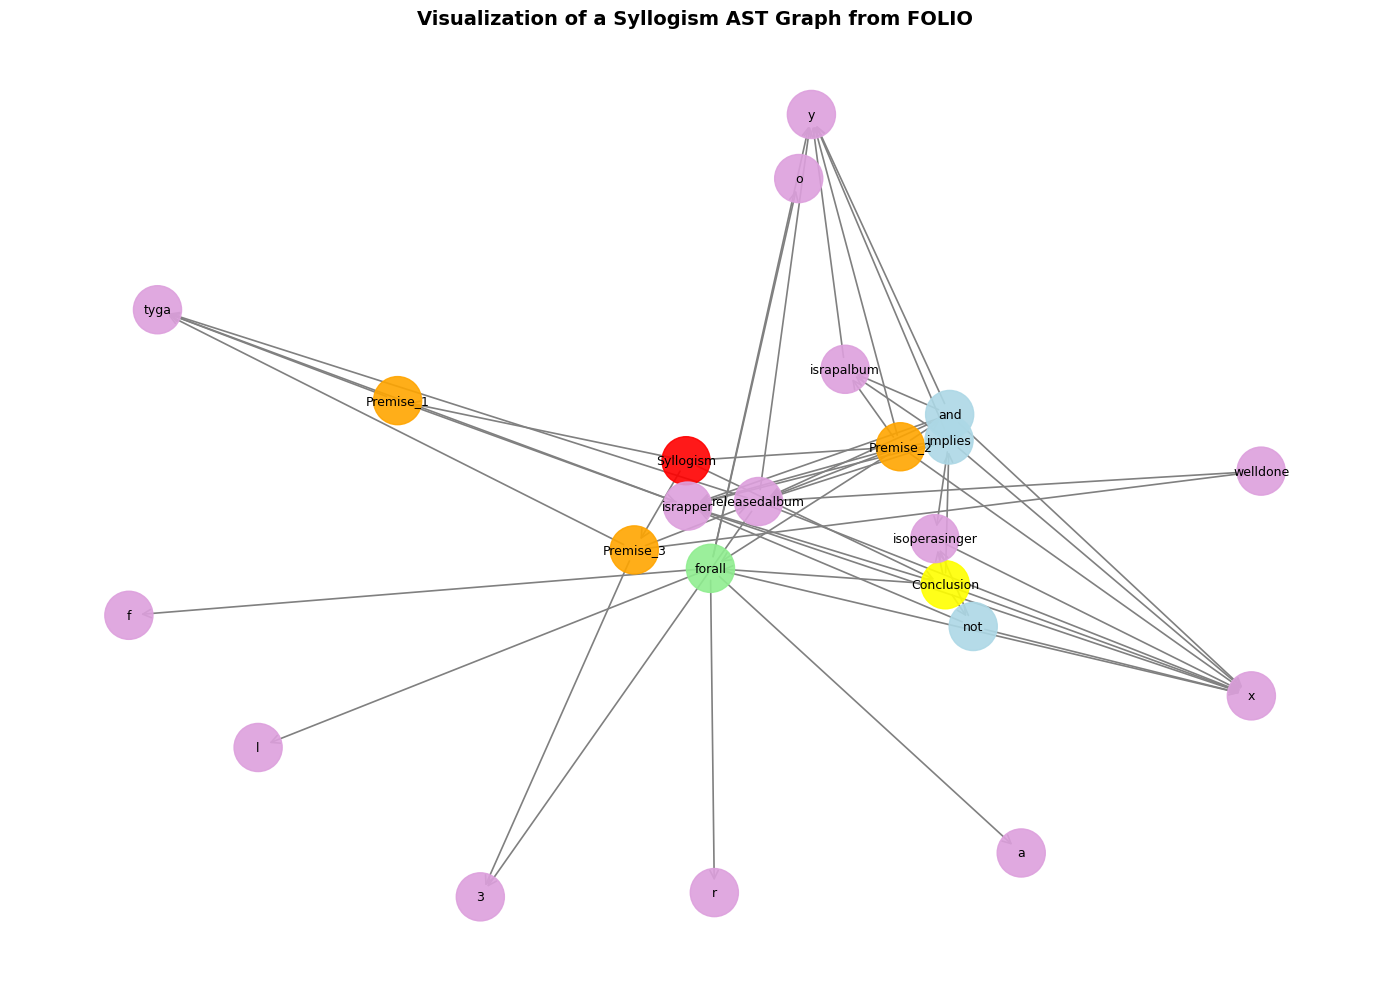

In [15]:
import matplotlib.pyplot as plt
import networkx as nx

# Access the first graph from our generated training set
sample_graph = train_graph_list[0]

# Prepare the layout and node colors based on node_type attributes
plt.figure(figsize=(14, 10))
pos = nx.spring_layout(sample_graph, seed=42, k=0.5)

# Extract node colors based on their roles in the AST
colors = []
for node, data in sample_graph.nodes(data=True):
    ntype = data.get("node_type", "")
    if "root" in ntype:
        colors.append("red")
    elif "premise" in ntype:
        colors.append("orange")
    elif "conclusion" in ntype:
        colors.append("yellow")
    elif "quantifier" in ntype:
        colors.append("lightgreen")
    elif "keyword" in ntype:
        colors.append("lightblue")
    else:
        colors.append("plum")  # Default term/proposition nodes

# Draw nodes, edges and labels
nx.draw_networkx_nodes(sample_graph, pos, node_color=colors, node_size=1200, alpha=0.9)
nx.draw_networkx_edges(sample_graph, pos, arrowstyle="->", arrowsize=15, edge_color="gray", width=1.2)

labels = {node: data.get("label", node) for node, data in sample_graph.nodes(data=True)}
nx.draw_networkx_labels(sample_graph, pos, labels=labels, font_size=9, font_family="sans-serif")

plt.title("Visualization of a Syllogism AST Graph from FOLIO", fontsize=14, fontweight='bold')
plt.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
!pip install scikit-learn torch-geometric
!pip install tensorboard

In [ ]:
import torch
import networkx as nx
from torch_geometric.data import Data

def prepare_dataset_from_graphs(graphs_list, labels_list):
    """
    Converts a list of independent NetworkX DiGraphs into a list of PyTorch Geometric Data objects.

    Parameters:
    -----------
    graphs_list : list of nx.DiGraph
        A list where each element is a separate syllogism DiGraph (G).
    labels_list : list of int
        A list of integer labels corresponding to each graph in graphs_list.
        Values must be 0 (False), 1 (True), or 2 (Unknown).

    Returns:
    --------
    pyg_data_list : list of torch_geometric.data.Data
        A list of data objects ready for the PyTorch Geometric DataLoader.
    """
    # Map textual node types to unique integer categorical IDs
    type_map = {
        "root": 0,
        "premise": 1,
        "conclusion": 2,
        "quantifier": 3,
        "operator": 4,
        "proposition": 5
    }

    pyg_data_list = []

    # Iterate through every graph-label pair in your dataset
    for idx, G in enumerate(graphs_list):
        node_list = list(G.nodes())
        node_to_idx = {node: i for i, node in enumerate(node_list)}

        # 1. Extract and map node category features
        node_features = []
        for node in node_list:
            if node == "SYLLOGISM":
                n_type = "root"
            elif node == "C":
                n_type = "conclusion"
            elif node.startswith("P") and "_" not in node:
                n_type = "premise"
            elif "_q_" in node:
                n_type = "quantifier"
            elif "_op_" in node:
                n_type = "operator"
            else:
                n_type = "proposition"

            node_features.append(type_map[n_type])

        # Convert node features to a long tensor shape [num_nodes, 1]
        x = torch.tensor(node_features, dtype=torch.long).view(-1, 1)

        # 2. Extract edge combinations safely if edges exist
        edges = list(G.edges())
        if len(edges) > 0:
            edge_index = torch.tensor(
                [[node_to_idx[u], node_to_idx[v]] for u, v in edges],
                dtype=torch.long
            ).t().contiguous()
        else:
            # Handle empty edge fallback edge index shape [2, 0]
            edge_index = torch.empty((2, 0), dtype=torch.long)

        # 3. Associate the structural classification target label
        y = torch.tensor([labels_list[idx]], dtype=torch.long)

        # 4. Enforce structural grouping into PyG Data format
        data_object = Data(x=x, edge_index=edge_index, y=y)
        pyg_data_list.append(data_object)

    return pyg_data_list


In [ ]:
!pip install -U transformers==4.45

In [ ]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import networkx as nx
from torch.utils.data import Dataset, DataLoader
from transformers.models.graphormer.configuration_graphormer import GraphormerConfig
from transformers.models.graphormer.modeling_graphormer import GraphormerForGraphClassification
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report
from sklearn.model_selection import train_test_split

try:
    from torch.utils.tensorboard import SummaryWriter
    _HAS_TENSORBOARD = True
except Exception:
    _HAS_TENSORBOARD = False
    print("Warning: Tensorboard SummaryWriter could not be loaded. Logging bypassed.")

# ==========================================
# 1. EARLY STOPPING BASED ON MACRO F1
# ==========================================
class F1EarlyStopping:
    def __init__(self, patience=10, checkpoint_path="best_graphormer_model.pt"):
        self.patience = patience
        self.checkpoint_path = checkpoint_path
        self.counter = 0
        self.best_f1 = -1.0
        self.early_stop = False

    def __call__(self, val_f1, model):
        if val_f1 > self.best_f1:
            print(f"Validation Macro F1 improved from {self.best_f1:.4f} to {val_f1:.4f}. Saving best weights!")
            self.best_f1 = val_f1
            self.save_checkpoint(model)
            self.counter = 0
        else:
            self.counter += 1
            print(f"EarlyStopping Counter: {self.counter} out of {self.patience}")
            if self.counter >= self.patience:
                self.early_stop = True

    def save_checkpoint(self, model):
        torch.save(model.state_dict(), self.checkpoint_path)

# ==========================================
# 2. CLASS-WEIGHTED MULTI-CLASS FOCAL LOSS
# ==========================================
class FocalLoss(nn.Module):
    def __init__(self, weight=None, gamma=2.0, reduction='mean'):
        super().__init__()
        self.weight = weight
        self.gamma = gamma
        self.reduction = reduction

    def forward(self, inputs, targets):
        ce_loss = F.cross_entropy(inputs, targets, weight=self.weight, reduction='none')
        pt = torch.exp(-ce_loss)
        focal_loss = ((1 - pt) ** self.gamma) * ce_loss
        if self.reduction == 'mean':
            return focal_loss.mean()
        elif self.reduction == 'sum':
            return focal_loss.sum()
        return focal_loss

# ==========================================
# 3. DATASET & BATCH COLLATION
# ==========================================
class GraphormerSyllogismDataset(Dataset):
    def __init__(self, graphs_list, labels_list, max_nodes=32):
        super().__init__()
        self.samples = []
        type_map = {"root": 0, "premise": 1, "conclusion": 2, "quantifier": 3, "operator": 4, "proposition": 5}

        for idx, G in enumerate(graphs_list):
            node_list = list(G.nodes())
            num_nodes = len(node_list)

            in_deg_dict = dict(G.in_degree())
            out_deg_dict = dict(G.out_degree())

            node_features = []
            for node in node_list:
                if node == "SYLLOGISM": n_type = "root"
                elif node == "C": n_type = "conclusion"
                elif node.startswith("P") and "_" not in node: n_type = "premise"
                elif "_q_" in node: n_type = "quantifier"
                elif "_op_" in node: n_type = "operator"
                else: n_type = "proposition"

                type_id = type_map[n_type]
                in_d = in_deg_dict.get(node, 0)
                out_d = out_deg_dict.get(node, 0)
                node_features.append([type_id, in_d, out_d])

            input_nodes = torch.tensor(node_features, dtype=torch.long)
            edge_attr = np.zeros((num_nodes, num_nodes, 1), dtype=np.int64)
            for u, v in G.edges():
                u_idx, v_idx = node_list.index(u), node_list.index(v)
                edge_attr[u_idx, v_idx, 0] = 1
            edge_input = torch.tensor(edge_attr, dtype=torch.long)

            shortest_paths = nx.all_pairs_shortest_path_length(G.to_undirected())
            spatial_pos_matrix = np.zeros((num_nodes, num_nodes), dtype=np.int64)
            path_dict = dict(shortest_paths)

            for i, u in enumerate(node_list):
                for j, v in enumerate(node_list):
                    spatial_pos_matrix[i, j] = path_dict[u][v] if v in path_dict[u] else max_nodes
            spatial_pos = torch.tensor(spatial_pos_matrix, dtype=torch.long)

            in_degree = torch.tensor([d for _, d in G.in_degree()], dtype=torch.long)
            out_degree = torch.tensor([d for _, d in G.out_degree()], dtype=torch.long)
            y = torch.tensor(labels_list[idx], dtype=torch.long)

            attn_bias = torch.zeros(num_nodes + 1, num_nodes + 1, dtype=torch.float)
            input_edges = torch.zeros(num_nodes, num_nodes, 1, 1, dtype=torch.long)
            attn_edge_type = torch.zeros(num_nodes, num_nodes, 1, dtype=torch.long)

            self.samples.append({
                "input_nodes": input_nodes, "edge_input": edge_input,
                "spatial_pos": spatial_pos, "in_degree": in_degree,
                "out_degree": out_degree, "labels": y,
                "attn_bias": attn_bias, "input_edges": input_edges,
                "attn_edge_type": attn_edge_type
            })

    def __len__(self): return len(self.samples)
    def __getitem__(self, idx): return self.samples[idx]

def graphormer_collate_fn(batch):
    max_batch_nodes = max(item["input_nodes"].size(0) for item in batch)
    batch_input_nodes, batch_edge_input, batch_spatial_pos = [], [], []
    batch_in_degree, batch_out_degree, batch_labels = [], [], []
    batch_attn_bias, batch_input_edges, batch_attn_edge_type = [], [], []

    for item in batch:
        n = item["input_nodes"].size(0)
        pad_size = max_batch_nodes - n

        batch_input_nodes.append(torch.cat([item["input_nodes"], torch.zeros((pad_size, 3), dtype=torch.long)], dim=0))
        batch_edge_input.append(F.pad(item["edge_input"], (0, 0, 0, pad_size, 0, pad_size), value=0))
        batch_spatial_pos.append(F.pad(item["spatial_pos"], (0, pad_size, 0, pad_size), value=32))
        batch_in_degree.append(torch.cat([item["in_degree"], torch.zeros(pad_size, dtype=torch.long)], dim=0))
        batch_out_degree.append(torch.cat([item["out_degree"], torch.zeros(pad_size, dtype=torch.long)], dim=0))
        batch_labels.append(item["labels"])

        padded_attn_bias = F.pad(item["attn_bias"], (0, pad_size, 0, pad_size), value=-1e9)
        padded_attn_bias[0, 0] = 0.0
        batch_attn_bias.append(padded_attn_bias)
        batch_input_edges.append(F.pad(item["input_edges"], (0, 0, 0, 0, 0, pad_size, 0, pad_size), value=0))
        batch_attn_edge_type.append(F.pad(item["attn_edge_type"], (0, 0, 0, pad_size, 0, pad_size), value=0))

    return {
        "input_nodes": torch.stack(batch_input_nodes), "edge_input": torch.stack(batch_edge_input),
        "spatial_pos": torch.stack(batch_spatial_pos), "in_degree": torch.stack(batch_in_degree),
        "out_degree": torch.stack(batch_out_degree), "labels": torch.stack(batch_labels),
        "attn_bias": torch.stack(batch_attn_bias), "input_edges": torch.stack(batch_input_edges),
        "attn_edge_type": torch.stack(batch_attn_edge_type)
    }

# ==========================================
# 4. PIPELINE ORCHESTRATION WITH BALANCING
# ==========================================
def run_graphormer_pipeline(train_graph_list, train_label_list, test_graph_list, test_label_list, val_graph_list, val_label_list):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Executing Balanced Graphormer Pipeline on: {device}\n")

    writer = SummaryWriter(log_dir="runs/graphormer_classification") if _HAS_TENSORBOARD else None
    early_stopping = F1EarlyStopping(patience=10, checkpoint_path="best_graphormer_model.pt")

    label_map = {'False': 0, 'True': 1, 'Uncertain': 2}
    train_labels = [label_map[lbl] for lbl in train_label_list]
    test_labels = [label_map[lbl] for lbl in test_label_list]
    val_labels = [label_map[lbl] for lbl in val_label_list]

    train_dataset = GraphormerSyllogismDataset(graphs_list=train_graph_list, labels_list=train_labels, max_nodes=32)
    train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True, collate_fn=graphormer_collate_fn)

    test_dataset = GraphormerSyllogismDataset(graphs_list=test_graph_list, labels_list=test_labels, max_nodes=32)
    test_loader = DataLoader(test_dataset, batch_size=8, collate_fn=graphormer_collate_fn)

    val_dataset = GraphormerSyllogismDataset(graphs_list=val_graph_list, labels_list=val_labels, max_nodes=32)
    val_loader = DataLoader(val_dataset, batch_size=8, collate_fn=graphormer_collate_fn)

    # Calculate accurate normalized class weights
    class_counts = np.bincount(train_labels, minlength=3)
    total_samples = len(train_labels)
    # Compute inverse frequency weights
    class_weights = total_samples / (3.0 * class_counts)
    weight_tensor = torch.tensor(class_weights, dtype=torch.float).to(device)
    print(f"Computed class weights: {class_weights}")

    config = GraphormerConfig(
        num_classes=3, num_atoms=64, num_edges=2, spatial_pos_max=64,
        num_attention_heads=4, embedding_dim=64, ffn_embedding_dim=64, num_trans_layers=3,
        dropout=0.15, attention_dropout=0.10
    )
    model = GraphormerForGraphClassification(config).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1.5e-4, weight_decay=0.15)

    # Use Focal Loss to heavily down-weight easy predictions and focus on minority classes
    criterion = FocalLoss(weight=weight_tensor, gamma=2.0)

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=40, eta_min=1e-6)

    num_epochs = 40
    print("--- Beginning Training Loop with Focal Loss & Macro F1 Early Stopping ---")

    for epoch in range(1, num_epochs + 1):
        model.train()
        total_train_loss, correct_train, total_graphs = 0, 0, 0

        for batch in train_loader:
            targets = batch.pop("labels").to(device)
            batch = {k: v.to(device) for k, v in batch.items()}

            optimizer.zero_grad()
            outputs = model(**batch)
            loss = criterion(outputs.logits, targets)
            loss.backward()

            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

            total_train_loss += loss.item() * targets.size(0)
            correct_train += int((outputs.logits.argmax(dim=-1) == targets).sum())
            total_graphs += targets.size(0)

        scheduler.step()
        avg_train_loss = total_train_loss / total_graphs
        train_acc = correct_train / total_graphs

        # Validation Loop
        model.eval()
        total_val_loss, val_preds, val_targets = 0, [], []
        with torch.no_grad():
            for batch in val_loader:
                targets = batch.pop("labels")
                batch_dev = {k: v.to(device) for k, v in batch.items()}
                outputs = model(**batch_dev)
                loss = criterion(outputs.logits, targets.to(device))

                total_val_loss += loss.item() * targets.size(0)
                val_preds.extend(outputs.logits.argmax(dim=-1).cpu().numpy())
                val_targets.extend(targets.numpy())

        avg_val_loss = total_val_loss / len(val_targets)
        val_acc = accuracy_score(val_targets, val_preds)
        _, _, val_f1, _ = precision_recall_fscore_support(val_targets, val_preds, average='macro', zero_division=0)

        print(f"Epoch {epoch:02d} | Train Loss: {avg_train_loss:.4f} Acc: {train_acc:.4f} | Val Loss: {avg_val_loss:.4f} Acc: {val_acc:.4f} Macro-F1: {val_f1:.4f}")

        if writer is not None:
            writer.add_scalar("Loss/Train", avg_train_loss, epoch)
            writer.add_scalar("Loss/Validation", avg_val_loss, epoch)
            writer.add_scalar("F1/Validation", val_f1, epoch)

        # Early stop monitoring validation Macro F1
        early_stopping(val_f1, model)
        if early_stopping.early_stop:
            print(f"== Early stopping triggered at epoch {epoch}. Restoring best F1 weights. ==")
            break

    if writer is not None:
        writer.close()

    # Restore model parameters mapping to the best Macro F1 score checkpoint
    if os.path.exists("best_graphormer_model.pt"):
        model.load_state_dict(torch.load("best_graphormer_model.pt"))

    # Evaluate on Test Dataset
    model.eval()
    all_preds, all_targets = [], []
    with torch.no_grad():
        for batch in test_loader:
            targets = batch.pop("labels")
            batch = {k: v.to(device) for k, v in batch.items()}
            outputs = model(**batch)
            all_preds.extend(outputs.logits.argmax(dim=-1).cpu().numpy())
            all_targets.extend(targets.numpy())

    accuracy = accuracy_score(all_targets, all_preds)
    precision, recall, f1, _ = precision_recall_fscore_support(all_targets, all_preds, average='macro', zero_division=0)
    print("\n================ GRAPHORMER TEST REPORT ================")
    print(f"Overall Accuracy : {accuracy:.4f}")
    print(f"Macro Precision  : {precision:.4f}")
    print(f"Macro Recall     : {recall:.4f}")
    print(f"Macro F1 Score   : {f1:.4f}")
    print("========================================================\n")
    print(classification_report(all_targets, all_preds, target_names=['0: False', '1: True', '2: Unknown'], zero_division=0))

if __name__ == "__main__":
    run_graphormer_pipeline(train_graph_list, train_label_list, test_graph_list, test_label_list, val_graph_list, val_label_list)

Executing Balanced Graphormer Pipeline on: cuda

Computed class weights: [1.18518519 0.84388186 1.02960103]
--- Beginning Training Loop with Focal Loss & Macro F1 Early Stopping ---
Epoch 01 | Train Loss: 0.5066 Acc: 0.3013 | Val Loss: 0.5009 Acc: 0.3399 Macro-F1: 0.1691
Validation Macro F1 improved from -1.0000 to 0.1691. Saving best weights!
Epoch 02 | Train Loss: 0.4956 Acc: 0.3200 | Val Loss: 0.5045 Acc: 0.3054 Macro-F1: 0.1560
EarlyStopping Counter: 1 out of 10
Epoch 03 | Train Loss: 0.4955 Acc: 0.3400 | Val Loss: 0.5980 Acc: 0.3399 Macro-F1: 0.1691
EarlyStopping Counter: 2 out of 10
Epoch 04 | Train Loss: 0.4960 Acc: 0.3287 | Val Loss: 0.5110 Acc: 0.3054 Macro-F1: 0.1862
Validation Macro F1 improved from 0.1691 to 0.1862. Saving best weights!
Epoch 05 | Train Loss: 0.4910 Acc: 0.3600 | Val Loss: 0.5255 Acc: 0.3399 Macro-F1: 0.2722
Validation Macro F1 improved from 0.1862 to 0.2722. Saving best weights!
Epoch 06 | Train Loss: 0.4863 Acc: 0.3675 | Val Loss: 0.5193 Acc: 0.3448 Macro

In [ ]:
import copy
import networkx as nx

def augment_via_contrapositive(graphs, labels):
    """
    Creates synthetic graph samples by finding logical implications in the graphs
    and reversing/negating the directed dependencies to simulate contraposition.
    """
    augmented_graphs = []
    augmented_labels = []

    for G, label in zip(graphs, labels):
        # Always retain original sample
        augmented_graphs.append(G)
        augmented_labels.append(label)

        # Identify if there is an implication (keyword 'implies' or mapping directed paths)
        has_implication = False
        for node, data in G.nodes(data=True):
            if data.get("node_type") == "keyword" and data.get("label") == "implies":
                has_implication = True
                break

        if has_implication:
            # Generate contrapositive variant of the graph
            aug_G = copy.deepcopy(G)

            # Simple structural representation of contraposition:
            # Reversing specific predicate-argument or logic flow sub-edges
            # while injecting a 'not' node to simulate logical negation mapping.
            # Identify 'term' nodes and toggle or prepend negated keywords
            term_nodes = [n for n, d in aug_G.nodes(data=True) if "term" in d.get("node_type", "")]

            if len(term_nodes) >= 2:
                # Introduce negation keyword node
                neg_node = "synthetic_not_marker"
                if not aug_G.has_node(neg_node):
                    aug_G.add_node(neg_node, label="not", node_type="keyword")

                # Connect negation to implication-involved terms
                for t in term_nodes[:2]:
                    aug_G.add_edge(neg_node, t)

                # Invert some of the local implication flows inside the AST representation
                edges_to_reverse = []
                for u, v in list(aug_G.edges()):
                    if u in term_nodes and v in term_nodes:
                        edges_to_reverse.append((u, v))

                for u, v in edges_to_reverse:
                    aug_G.remove_edge(u, v)
                    aug_G.add_edge(v, u)

            augmented_graphs.append(aug_G)
            # Contraposition preserves the original logical validity label
            augmented_labels.append(label)

    return augmented_graphs, augmented_labels

# Run augmentation on the training set
orig_train_size = len(train_graph_list)
aug_train_graph_list, aug_train_label_list = augment_via_contrapositive(train_graph_list, train_label_list)
print(f"Augmented Train Dataset: from {orig_train_size} to {len(aug_train_graph_list)} graphs.")


In [ ]:
import itertools
import copy

def run_graphormer_grid_search(train_graph_list, train_label_list, val_graph_list, val_label_list):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Starting Hyperparameter Grid Search on {device}...\n")

    # Map labels
    label_map = {'False': 0, 'True': 1, 'Uncertain': 2}
    train_labels = [label_map[lbl] for lbl in train_label_list]
    val_labels = [label_map[lbl] for lbl in val_label_list]

    # Prepare PyTorch Datasets
    train_dataset = GraphormerSyllogismDataset(graphs_list=train_graph_list, labels_list=train_labels, max_nodes=32)
    val_dataset = GraphormerSyllogismDataset(graphs_list=val_graph_list, labels_list=val_labels, max_nodes=32)

    # Dynamic class weights to combat imbalance
    class_counts = np.bincount(train_labels, minlength=3)
    class_weights = len(train_labels) / (3.0 * class_counts)
    weight_tensor = torch.tensor(class_weights, dtype=torch.float).to(device)

    # Define the Hyperparameter Grid
    grid = {
        'lr': [5e-5, 1e-4, 2e-4],
        'dropout': [0.1, 0.2],
        'gamma': [1.5, 2.0, 2.5]
    }

    # Generate combinations
    keys, values = zip(*grid.items())
    experiments = [dict(zip(keys, v)) for v in itertools.product(*values)]

    best_f1 = -1.0
    best_params = None
    best_state_dict = None

    print(f"Total experiments to run: {len(experiments)}\n")

    for idx, params in enumerate(experiments):
        print(f"[Experiment {idx+1}/{len(experiments)}] Tuning Parameters: {params}")

        # Standardize training loaders
        train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True, collate_fn=graphormer_collate_fn)
        val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False, collate_fn=graphormer_collate_fn)

        config = GraphormerConfig(
            num_classes=3,
            num_atoms=64,
            num_edges=2,
            spatial_pos_max=64,
            num_attention_heads=4,
            embedding_dim=64,
            ffn_embedding_dim=64,
            num_trans_layers=3,
            dropout=params['dropout'],
            attention_dropout=params['dropout']
        )

        model = GraphormerForGraphClassification(config).to(device)
        optimizer = torch.optim.AdamW(model.parameters(), lr=params['lr'], weight_decay=0.15)
        criterion = FocalLoss(weight=weight_tensor, gamma=params['gamma'])
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=15, eta_min=1e-6)

        epoch_best_f1 = -1.0
        patience_counter = 0
        patience = 5  # Reduced epoch patience for grid search speed

        for epoch in range(1, 16):  # 15 epochs max per experiment
            model.train()
            for batch in train_loader:
                targets = batch.pop("labels").to(device)
                batch_dev = {k: v.to(device) for k, v in batch.items()}
                optimizer.zero_grad()
                outputs = model(**batch_dev)
                loss = criterion(outputs.logits, targets)
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()

            scheduler.step()

            # Validation Step
            model.eval()
            val_preds, val_targets = [], []
            with torch.no_grad():
                for batch in val_loader:
                    targets = batch.pop("labels")
                    batch_dev = {k: v.to(device) for k, v in batch.items()}
                    outputs = model(**batch_dev)
                    val_preds.extend(outputs.logits.argmax(dim=-1).cpu().numpy())
                    val_targets.extend(targets.numpy())

            _, _, val_f1, _ = precision_recall_fscore_support(val_targets, val_preds, average='macro', zero_division=0)

            if val_f1 > epoch_best_f1:
                epoch_best_f1 = val_f1
                patience_counter = 0
                temp_state = copy.deepcopy(model.state_dict())
            else:
                patience_counter += 1
                if patience_counter >= patience:
                    break

        print(f"-> Finished. Best Val Macro-F1: {epoch_best_f1:.4f}\n")

        if epoch_best_f1 > best_f1:
            best_f1 = epoch_best_f1
            best_params = params
            best_state_dict = temp_state

    print("================ GRID SEARCH COMPLETE ================")
    print(f"Best Parameters Found : {best_params}")
    print(f"Best Validation Macro-F1 : {best_f1:.4f}")
    print("======================================================")

    # Save the absolute best weights back to model file
    if best_state_dict is not None:
        torch.save(best_state_dict, "best_graphormer_model.pt")
        print("Best model checkpoints successfully updated!")

# Run the grid search execution
run_graphormer_grid_search(train_graph_list, train_label_list, val_graph_list, val_label_list)

Starting Hyperparameter Grid Search on cuda...

Total experiments to run: 18

[Experiment 1/18] Tuning Parameters: {'lr': 5e-05, 'dropout': 0.1, 'gamma': 1.5}
-> Finished. Best Val Macro-F1: 0.3053

[Experiment 2/18] Tuning Parameters: {'lr': 5e-05, 'dropout': 0.1, 'gamma': 2.0}
-> Finished. Best Val Macro-F1: 0.2829

[Experiment 3/18] Tuning Parameters: {'lr': 5e-05, 'dropout': 0.1, 'gamma': 2.5}
-> Finished. Best Val Macro-F1: 0.2960

[Experiment 4/18] Tuning Parameters: {'lr': 5e-05, 'dropout': 0.2, 'gamma': 1.5}
-> Finished. Best Val Macro-F1: 0.3031

[Experiment 5/18] Tuning Parameters: {'lr': 5e-05, 'dropout': 0.2, 'gamma': 2.0}
-> Finished. Best Val Macro-F1: 0.2737

[Experiment 6/18] Tuning Parameters: {'lr': 5e-05, 'dropout': 0.2, 'gamma': 2.5}
-> Finished. Best Val Macro-F1: 0.2658

[Experiment 7/18] Tuning Parameters: {'lr': 0.0001, 'dropout': 0.1, 'gamma': 1.5}
-> Finished. Best Val Macro-F1: 0.3274

[Experiment 8/18] Tuning Parameters: {'lr': 0.0001, 'dropout': 0.1, 'gamma

In [ ]:
# Execute the fine-tuning pipeline on our processed graph lists
# This trains the Graphormer model using Focal Loss to handle class imbalance

run_graphormer_pipeline(
    train_graph_list=train_graph_list,
    train_label_list=train_label_list,
    test_graph_list=test_graph_list,
    test_label_list=test_label_list,
    val_graph_list=val_graph_list,
    val_label_list=val_label_list
)

Executing Balanced Graphormer Pipeline on: cuda

Computed class weights: [1.18518519 0.84388186 1.02960103]
--- Beginning Training Loop with Focal Loss & Macro F1 Early Stopping ---
Epoch 01 | Train Loss: 0.4973 Acc: 0.3275 | Val Loss: 0.5101 Acc: 0.3054 Macro-F1: 0.1799
Validation Macro F1 improved from -1.0000 to 0.1799. Saving best weights!
Epoch 02 | Train Loss: 0.4918 Acc: 0.3387 | Val Loss: 0.5306 Acc: 0.3399 Macro-F1: 0.1788
EarlyStopping Counter: 1 out of 10
Epoch 03 | Train Loss: 0.4999 Acc: 0.3212 | Val Loss: 0.5057 Acc: 0.3005 Macro-F1: 0.2081
Validation Macro F1 improved from 0.1799 to 0.2081. Saving best weights!
Epoch 04 | Train Loss: 0.4836 Acc: 0.3887 | Val Loss: 0.5082 Acc: 0.3103 Macro-F1: 0.2336
Validation Macro F1 improved from 0.2081 to 0.2336. Saving best weights!
Epoch 05 | Train Loss: 0.4829 Acc: 0.3700 | Val Loss: 0.5194 Acc: 0.3153 Macro-F1: 0.2360
Validation Macro F1 improved from 0.2336 to 0.2360. Saving best weights!
Epoch 06 | Train Loss: 0.4834 Acc: 0.357

In [33]:
# Run the Graphormer pipeline with augmented training data
run_graphormer_pipeline(
    train_graph_list=aug_train_graph_list,
    train_label_list=aug_train_label_list,
    test_graph_list=test_graph_list,
    test_label_list=test_label_list,
    val_graph_list=val_graph_list,
    val_label_list=val_label_list
)

NameError: name 'run_graphormer_pipeline' is not defined

In [ ]:
import numpy as np
import networkx as nx
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

def extract_graph_features(graphs_list):
    """
    Extracts a vector of statistical and structural features for each NetworkX graph.
    """
    features = []
    for G in graphs_list:
        num_nodes = G.number_of_nodes()
        num_edges = G.number_of_edges()
        density = nx.density(G)

        # Degree statistics
        degrees = [d for _, d in G.degree()]
        mean_degree = np.mean(degrees) if degrees else 0
        max_degree = np.max(degrees) if degrees else 0
        std_degree = np.std(degrees) if degrees else 0

        # Connectivity and clustering
        # Convert to undirected for clustering coefficient safely
        undirected_G = G.to_undirected()
        avg_clustering = nx.average_clustering(undirected_G)
        transitivity = nx.transitivity(undirected_G)

        # Basic categorical counts from node attributes if present
        node_types = [data.get("node_type", "") for _, data in G.nodes(data=True)]
        num_premises = sum(1 for t in node_types if "premise" in str(t))
        num_conclusions = sum(1 for t in node_types if "conclusion" in str(t))
        num_quantifiers = sum(1 for t in node_types if "quantifier" in str(t))
        num_keywords = sum(1 for t in node_types if "keyword" in str(t))
        num_terms = sum(1 for t in node_types if "term" in str(t))

        features.append([
            num_nodes, num_edges, density, mean_degree, max_degree, std_degree,
            avg_clustering, transitivity, num_premises, num_conclusions,
            num_quantifiers, num_keywords, num_terms
        ])

    feature_names = [
        "num_nodes", "num_edges", "density", "mean_degree", "max_degree", "std_degree",
        "avg_clustering", "transitivity", "num_premises", "num_conclusions",
        "num_quantifiers", "num_keywords", "num_terms"
    ]
    return pd.DataFrame(features, columns=feature_names)

# Prepare features and target labels
label_map = {'False': 0, 'True': 1, 'Uncertain': 2}
y_train = np.array([label_map[lbl] for lbl in train_label_list])
y_test = np.array([label_map[lbl] for lbl in test_label_list])

X_train = extract_graph_features(train_graph_list)
X_test = extract_graph_features(test_graph_list)

# Train Random Forest baseline
rf_baseline = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42, class_weight="balanced")
rf_baseline.fit(X_train, y_train)

# Inference and Performance Evaluation
y_pred = rf_baseline.predict(X_test)

print("================ RANDOM FOREST BASELINE REPORT ================")
print(f"Overall Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print("===============================================================\n")
print(classification_report(y_test, y_pred, target_names=['0: False', '1: True', '2: Unknown'], zero_division=0))

# Display feature importances
importances = rf_baseline.feature_importances_
indices = np.argsort(importances)[::-1]
print("Top Structural Feature Importances:")
for f in range(X_train.shape[1]):
    print(f"{f + 1:2d}) {X_train.columns[indices[f]]:20s}: {importances[indices[f]]:.4f}")

================ RANDOM FOREST BASELINE REPORT ================
Overall Accuracy : 0.1841

              precision    recall  f1-score   support

    0: False       0.19      0.23      0.21        64
     1: True       0.11      0.10      0.11        72
  2: Unknown       0.24      0.23      0.24        65

    accuracy                           0.18       201
   macro avg       0.18      0.19      0.18       201
weighted avg       0.18      0.18      0.18       201

Top Structural Feature Importances:
 1) mean_degree         : 0.1367
 2) avg_clustering      : 0.1225
 3) transitivity        : 0.1098
 4) density             : 0.1095
 5) std_degree          : 0.1048
 6) num_edges           : 0.0987
 7) num_premises        : 0.0662
 8) num_nodes           : 0.0659
 9) num_terms           : 0.0601
10) max_degree          : 0.0585
11) num_keywords        : 0.0356
12) num_quantifiers     : 0.0318
13) num_conclusions     : 0.0000


In [ ]:
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

def extract_semantic_corpus(graphs_list):
    """
    Aggregates all node labels inside each graph into a single string corpus.
    """
    corpus = []
    for G in graphs_list:
        labels = [str(data.get("label", "")) for _, data in G.nodes(data=True)]
        corpus.append(" ".join(labels))
    return corpus

# 1. Create text corpuses for vectorization
train_corpus = extract_semantic_corpus(train_graph_list)
test_corpus = extract_semantic_corpus(test_graph_list)

# 2. Extract TF-IDF features
vectorizer = TfidfVectorizer(max_features=50, ngram_range=(1, 2))
X_train_tfidf = vectorizer.fit_transform(train_corpus).toarray()
X_test_tfidf = vectorizer.transform(test_corpus).toarray()

# 3. Build structural features
X_train_struct = extract_graph_features(train_graph_list).values
X_test_struct = extract_graph_features(test_graph_list).values

# 4. Concatenate structural features and semantic TF-IDF embeddings
X_train_combined = np.hstack((X_train_struct, X_train_tfidf))
X_test_combined = np.hstack((X_test_struct, X_test_tfidf))

# 5. Train the Random Forest Baseline on the combined datasets
rf_semantic_baseline = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42, class_weight="balanced")
rf_semantic_baseline.fit(X_train_combined, y_train)

# 6. Evaluation
y_pred_semantic = rf_semantic_baseline.predict(X_test_combined)

print("================ RANDOM FOREST WITH SEMANTICS REPORT ================")
print(f"Overall Accuracy : {accuracy_score(y_test, y_pred_semantic):.4f}")
print("=====================================================================\n")
print(classification_report(y_test, y_pred_semantic, target_names=['0: False', '1: True', '2: Unknown'], zero_division=0))

================ RANDOM FOREST WITH SEMANTICS REPORT ================
Overall Accuracy : 0.2189

              precision    recall  f1-score   support

    0: False       0.19      0.20      0.20        64
     1: True       0.19      0.18      0.19        72
  2: Unknown       0.28      0.28      0.28        65

    accuracy                           0.22       201
   macro avg       0.22      0.22      0.22       201
weighted avg       0.22      0.22      0.22       201



In [ ]:
!pip install -q node2vec

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.8/15.8 MB 93.1 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 91.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
contourpy 1.4.0 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
diffusers 0.41.0 requires huggingface-hub<2.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
ml-dtypes 0.6.0 requires numpy>=2.0.0, but you have numpy 1.26.4 which is incompatible.
ml-dtypes 0.6.0 requires numpy>=2.1.0; python_version >= "3.13", but you have numpy 1.

In [ ]:
import numpy as np
from node2vec import Node2Vec
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score
import warnings

def extract_node2vec_embeddings(graphs_list, dimensions=32, walk_length=10, num_walks=40, workers=1):
    """
    Generates graph-level embedding vectors by averaging node-level Node2Vec embeddings.
    """
    graph_embeddings = []
    # Ignore warnings from Node2Vec random walk configurations
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        for i, G in enumerate(graphs_list):
            # Convert to undirected safely as standard Node2Vec requires connected/walkable components
            undirected_G = G.to_undirected()
            if undirected_G.number_of_nodes() == 0:
                graph_embeddings.append(np.zeros(dimensions))
                continue

            # Fit Node2Vec representation mapper on the individual graph
            n2v = Node2Vec(
                undirected_G,
                dimensions=dimensions,
                walk_length=walk_length,
                num_walks=num_walks,
                workers=workers,
                quiet=True
            )
            model = n2v.fit(window=5, min_count=1, batch_words=4)

            # Pool node vectors via spatial mean
            node_vectors = [model.wv[str(node)] for node in undirected_G.nodes() if str(node) in model.wv]
            if node_vectors:
                graph_emb = np.mean(node_vectors, axis=0)
            else:
                graph_emb = np.zeros(dimensions)
            graph_embeddings.append(graph_emb)

    return np.array(graph_embeddings)

print("Generating Node2Vec embeddings for Train set...")
X_train_n2v = extract_node2vec_embeddings(train_graph_list, dimensions=32)
print("Generating Node2Vec embeddings for Test set...")
X_test_n2v = extract_node2vec_embeddings(test_graph_list, dimensions=32)

# Train Random Forest on node2vec features
rf_n2v = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42, class_weight="balanced")
rf_n2v.fit(X_train_n2v, y_train)

y_pred_n2v = rf_n2v.predict(X_test_n2v)

print("\n================ RANDOM FOREST WITH NODE2VEC REPORT ================")
print(f"Overall Accuracy : {accuracy_score(y_test, y_pred_n2v):.4f}")
print("====================================================================\n")
print(classification_report(y_test, y_pred_n2v, target_names=['0: False', '1: True', '2: Unknown'], zero_division=0))

Generating Node2Vec embeddings for Train set...
Generating Node2Vec embeddings for Test set...

================ RANDOM FOREST WITH NODE2VEC REPORT ================
Overall Accuracy : 0.3184

              precision    recall  f1-score   support

    0: False       0.25      0.20      0.22        64
     1: True       0.36      0.44      0.40        72
  2: Unknown       0.33      0.29      0.31        65

    accuracy                           0.32       201
   macro avg       0.31      0.31      0.31       201
weighted avg       0.31      0.32      0.31       201



In [ ]:
import numpy as np
import pandas as pd
import networkx as nx
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.feature_extraction.text import TfidfVectorizer
from node2vec import Node2Vec
import warnings

# ==========================================
# 1. SETUP TARGET LABELS & FEATURE EXTRACTORS
# ==========================================
label_map = {'False': 0, 'True': 1, 'Uncertain': 2}
y_train = np.array([label_map[lbl] for lbl in train_label_list])
y_test = np.array([label_map[lbl] for lbl in test_label_list])

def extract_graph_features(graphs_list):
    features = []
    for G in graphs_list:
        num_nodes = G.number_of_nodes()
        num_edges = G.number_of_edges()
        density = nx.density(G)
        degrees = [d for _, d in G.degree()]
        mean_degree = np.mean(degrees) if degrees else 0
        max_degree = np.max(degrees) if degrees else 0
        std_degree = np.std(degrees) if degrees else 0

        undirected_G = G.to_undirected()
        avg_clustering = nx.average_clustering(undirected_G)
        transitivity = nx.transitivity(undirected_G)

        node_types = [data.get("node_type", "") for _, data in G.nodes(data=True)]
        num_premises = sum(1 for t in node_types if "premise" in str(t))
        num_conclusions = sum(1 for t in node_types if "conclusion" in str(t))
        num_quantifiers = sum(1 for t in node_types if "quantifier" in str(t))
        num_keywords = sum(1 for t in node_types if "keyword" in str(t))
        num_terms = sum(1 for t in node_types if "term" in str(t))

        features.append([
            num_nodes, num_edges, density, mean_degree, max_degree, std_degree,
            avg_clustering, transitivity, num_premises, num_conclusions,
            num_quantifiers, num_keywords, num_terms
        ])

    feature_names = [
        "num_nodes", "num_edges", "density", "mean_degree", "max_degree", "std_degree",
        "avg_clustering", "transitivity", "num_premises", "num_conclusions",
        "num_quantifiers", "num_keywords", "num_terms"
    ]
    return pd.DataFrame(features, columns=feature_names)

def extract_semantic_corpus(graphs_list):
    corpus = []
    for G in graphs_list:
        labels = [str(data.get("label", "")) for _, data in G.nodes(data=True)]
        corpus.append(" ".join(labels))
    return corpus

def extract_node2vec_embeddings(graphs_list, dimensions=32, walk_length=10, num_walks=40, workers=1):
    graph_embeddings = []
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        for G in graphs_list:
            undirected_G = G.to_undirected()
            if undirected_G.number_of_nodes() == 0:
                graph_embeddings.append(np.zeros(dimensions))
                continue

            n2v = Node2Vec(undirected_G, dimensions=dimensions, walk_length=walk_length, num_walks=num_walks, workers=workers, quiet=True)
            model = n2v.fit(window=5, min_count=1, batch_words=4)

            node_vectors = [model.wv[str(node)] for node in undirected_G.nodes() if str(node) in model.wv]
            if node_vectors:
                graph_emb = np.mean(node_vectors, axis=0)
            else:
                graph_emb = np.zeros(dimensions)
            graph_embeddings.append(graph_emb)
    return np.array(graph_embeddings)

# ==========================================
# 2. FEATURE GENERATION
# ==========================================
print("Extracting structural features...")
X_train = extract_graph_features(train_graph_list)
X_test = extract_graph_features(test_graph_list)

print("Extracting semantic TF-IDF features...")
train_corpus = extract_semantic_corpus(train_graph_list)
test_corpus = extract_semantic_corpus(test_graph_list)
vectorizer = TfidfVectorizer(max_features=50, ngram_range=(1, 2))
X_train_tfidf = vectorizer.fit_transform(train_corpus).toarray()
X_test_tfidf = vectorizer.transform(test_corpus).toarray()

X_train_combined = np.hstack((X_train.values, X_train_tfidf))
X_test_combined = np.hstack((X_test.values, X_test_tfidf))

print("Extracting Node2Vec embeddings (this may take a minute)...")
X_train_n2v = extract_node2vec_embeddings(train_graph_list, dimensions=32)
X_test_n2v = extract_node2vec_embeddings(test_graph_list, dimensions=32)
print("Feature extraction complete!\n")

# ==========================================
# 3. TRAINING & EVALUATION
# ==========================================
# 1. Structural RF
print("=== Running Random Forest (Structural Features Only) ===")
rf_baseline = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42, class_weight='balanced')
rf_baseline.fit(X_train, y_train)
y_pred_struct = rf_baseline.predict(X_test)
print(f"Structural RF Accuracy: {accuracy_score(y_test, y_pred_struct):.4f}\n")
print(classification_report(y_test, y_pred_struct, target_names=['0: False', '1: True', '2: Unknown'], zero_division=0))

# 2. Semantic TF-IDF RF
print("\n=== Running Random Forest (Structural + Semantic TF-IDF) ===")
rf_semantic_baseline = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42, class_weight='balanced')
rf_semantic_baseline.fit(X_train_combined, y_train)
y_pred_sem = rf_semantic_baseline.predict(X_test_combined)
print(f"Semantic RF Accuracy: {accuracy_score(y_test, y_pred_sem):.4f}\n")
print(classification_report(y_test, y_pred_sem, target_names=['0: False', '1: True', '2: Unknown'], zero_division=0))

# 3. Node2Vec RF
print("\n=== Running Random Forest (Node2Vec Node Embeddings) ===")
rf_n2v = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42, class_weight='balanced')
rf_n2v.fit(X_train_n2v, y_train)
y_pred_n2v = rf_n2v.predict(X_test_n2v)
print(f"Node2Vec RF Accuracy: {accuracy_score(y_test, y_pred_n2v):.4f}\n")
print(classification_report(y_test, y_pred_n2v, target_names=['0: False', '1: True', '2: Unknown'], zero_division=0))

Extracting structural features...
Extracting semantic TF-IDF features...
Extracting Node2Vec embeddings (this may take a minute)...
Feature extraction complete!

=== Running Random Forest (Structural Features Only) ===
Structural RF Accuracy: 0.1841

              precision    recall  f1-score   support

    0: False       0.19      0.23      0.21        64
     1: True       0.11      0.10      0.11        72
  2: Unknown       0.24      0.23      0.24        65

    accuracy                           0.18       201
   macro avg       0.18      0.19      0.18       201
weighted avg       0.18      0.18      0.18       201


=== Running Random Forest (Structural + Semantic TF-IDF) ===
Semantic RF Accuracy: 0.2189

              precision    recall  f1-score   support

    0: False       0.19      0.20      0.20        64
     1: True       0.19      0.18      0.19        72
  2: Unknown       0.28      0.28      0.28        65

    accuracy                           0.22       201
   m

In [ ]:
# Diagnostics cell to find the source of NaN losses
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Re-create a small test setup
label_map = {'False': 0, 'True': 1, 'Uncertain': 2}
train_labels = [label_map[lbl] for lbl in train_label_list]
train_dataset = GraphormerSyllogismDataset(graphs_list=train_graph_list, labels_list=train_labels, max_nodes=32)
train_loader = DataLoader(train_dataset, batch_size=4, collate_fn=graphormer_collate_fn)

# Get a single batch
batch = next(iter(train_loader))
targets = batch.pop("labels").to(device)
batch_device = {k: v.to(device) for k, v in batch.items()}

# Let's inspect the shapes and value ranges
print("--- Tensor Diagnostics inside a Batch ---")
for k, v in batch_device.items():
    print(f"{k:20s} | Shape: {list(v.shape)} | Min: {v.min().item()} | Max: {v.max().item()} | Any NaN: {torch.isnan(v).any().item()}")

# Run a single forward pass with the model
# Fix: Increased num_atoms from 6 to 64 to prevent out-of-bounds indexing assertions in PyTorch CUDA embeddings
config = GraphormerConfig(
    num_classes=3, num_atoms=64, num_edges=2, spatial_pos_max=64,
    num_attention_heads=4, embedding_dim=64, ffn_embedding_dim=64, num_trans_layers=3
)
model = GraphormerForGraphClassification(config).to(device)

# Evaluate the embeddings and model output
with torch.no_grad():
    outputs = model(**batch_device)
    print("\n--- Model Outputs ---")
    print(f"Logits Shape: {outputs.logits.shape}")
    print(f"Logits: {outputs.logits}")
    print(f"Logits Any NaN: {torch.isnan(outputs.logits).any().item()}")

--- Tensor Diagnostics inside a Batch ---
input_nodes          | Shape: [4, 35, 3] | Min: 0 | Max: 21 | Any NaN: False
edge_input           | Shape: [4, 35, 35, 1] | Min: 0 | Max: 1 | Any NaN: False
spatial_pos          | Shape: [4, 35, 35] | Min: 0 | Max: 32 | Any NaN: False
in_degree            | Shape: [4, 35] | Min: 0 | Max: 21 | Any NaN: False
out_degree           | Shape: [4, 35] | Min: 0 | Max: 20 | Any NaN: False
attn_bias            | Shape: [4, 36, 36] | Min: -1000000000.0 | Max: 0.0 | Any NaN: False
input_edges          | Shape: [4, 35, 35, 1, 1] | Min: 0 | Max: 0 | Any NaN: False
attn_edge_type       | Shape: [4, 35, 35, 1] | Min: 0 | Max: 0 | Any NaN: False

--- Model Outputs ---
Logits Shape: torch.Size([4, 3])
Logits: tensor([[-0.1555,  0.1374,  0.0271],
        [-0.0864,  0.1898,  0.0542],
        [-0.1015,  0.1497,  0.0335],
        [-0.0877,  0.0482, -0.0172]], device='cuda:0')
Logits Any NaN: False


In [ ]:
import torch
from torch.utils.data import DataLoader
from transformers import GraphormerConfig, GraphormerForGraphClassification
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Running inference on: {device}")

# 1. Prepare target labels for Test set
label_map = {'False': 0, 'True': 1, 'Uncertain': 2}
test_labels = [label_map[lbl] for lbl in test_label_list]

# 2. Build dataset and dataloader
test_dataset = GraphormerSyllogismDataset(graphs_list=test_graph_list, labels_list=test_labels, max_nodes=32)
test_loader = DataLoader(test_dataset, batch_size=8, shuffle=False, collate_fn=graphormer_collate_fn)

# 3. Initialize Model with correct configuration (num_atoms=64)
config = GraphormerConfig(
    num_classes=3,
    num_atoms=64,
    num_edges=2,
    spatial_pos_max=64,
    num_attention_heads=4,
    embedding_dim=64,
    ffn_embedding_dim=64,
    num_trans_layers=3
)
model = GraphormerForGraphClassification(config).to(device)

# 4. Load saved model weights
checkpoint_path = "best_graphormer_model.pt"
try:
    model.load_state_dict(torch.load(checkpoint_path, map_location=device))
    print(f"Successfully loaded best model weights from {checkpoint_path}.")
except Exception as e:
    print(f"Could not load checkpoint: {e}. Running inference with randomized weights instead.")

# 5. Evaluate
model.eval()
all_preds, all_targets = [], []
with torch.no_grad():
    for batch in test_loader:
        targets = batch.pop("labels")
        batch_device = {k: v.to(device) for k, v in batch.items()}
        outputs = model(**batch_device)

        preds = outputs.logits.argmax(dim=-1).cpu().numpy()
        all_preds.extend(preds)
        all_targets.extend(targets.numpy())

# 6. Display metrics
accuracy = accuracy_score(all_targets, all_preds)
precision, recall, f1, _ = precision_recall_fscore_support(all_targets, all_preds, average='macro', zero_division=0)

print("\n================ GRAPHORMER TEST REPORT ================")
print(f"Overall Accuracy : {accuracy:.4f}")
print(f"Macro Precision  : {precision:.4f}")
print(f"Macro Recall     : {recall:.4f}")
print(f"Macro F1 Score   : {f1:.4f}")
print("========================================================\n")
print(classification_report(all_targets, all_preds, target_names=['0: False', '1: True', '2: Unknown'], zero_division=0))

Running inference on: cuda
Successfully loaded best model weights from best_graphormer_model.pt.

================ GRAPHORMER TEST REPORT ================
Overall Accuracy : 0.2886
Macro Precision  : 0.1906
Macro Recall     : 0.2993
Macro F1 Score   : 0.2327

              precision    recall  f1-score   support

    0: False       0.24      0.36      0.29        64
     1: True       0.00      0.00      0.00        72
  2: Unknown       0.33      0.54      0.41        65

    accuracy                           0.29       201
   macro avg       0.19      0.30      0.23       201
weighted avg       0.18      0.29      0.22       201



In [32]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GATConv, global_mean_pool
from torch_geometric.data import Data
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report

# 1. Early Stopping Utility
class F1EarlyStopping:
    def __init__(self, patience=10, checkpoint_path="best_gat_model.pt"):
        self.patience = patience
        self.checkpoint_path = checkpoint_path
        self.counter = 0
        self.best_f1 = -1.0
        self.early_stop = False

    def __call__(self, val_f1, model):
        if val_f1 > self.best_f1:
            print(f"Validation Macro F1 improved from {self.best_f1:.4f} to {val_f1:.4f}. Saving best weights!")
            self.best_f1 = val_f1
            self.save_checkpoint(model)
            self.counter = 0
        else:
            self.counter += 1
            print(f"EarlyStopping Counter: {self.counter} out of {self.patience}")
            if self.counter >= self.patience:
                self.early_stop = True

    def save_checkpoint(self, model):
        torch.save(model.state_dict(), self.checkpoint_path)

# 2. Focal Loss
class FocalLoss(nn.Module):
    def __init__(self, weight=None, gamma=2.0, reduction='mean'):
        super().__init__()
        self.weight = weight
        self.gamma = gamma
        self.reduction = reduction

    def forward(self, inputs, targets):
        ce_loss = F.cross_entropy(inputs, targets, weight=self.weight, reduction='none')
        pt = torch.exp(-ce_loss)
        focal_loss = ((1 - pt) ** self.gamma) * ce_loss
        if self.reduction == 'mean':
            return focal_loss.mean()
        elif self.reduction == 'sum':
            return focal_loss.sum()
        return focal_loss

# 3. GAT Model Architecture
class GATClassifier(nn.Module):
    def __init__(self, num_node_features=3, num_classes=3, hidden_dim=64, num_heads=4, dropout=0.15):
        super().__init__()
        self.node_encoder = nn.Linear(num_node_features, hidden_dim)
        self.conv1 = GATConv(hidden_dim, hidden_dim, heads=num_heads, dropout=dropout, concat=True)
        self.conv2 = GATConv(hidden_dim * num_heads, hidden_dim, heads=num_heads, dropout=dropout, concat=False)
        self.fc = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, num_classes)
        )

    def forward(self, data):
        x, edge_index, batch = data.x, data.edge_index, data.batch
        # Encode node attributes
        x = self.node_encoder(x.float())
        x = F.elu(self.conv1(x, edge_index))
        x = F.elu(self.conv2(x, edge_index))
        # Readout: Pool nodes to graph-level embedding
        x_pooled = global_mean_pool(x, batch)
        return self.fc(x_pooled)

# 4. Convert graphs to PyG Dataset format
def prepare_pyg_dataset(graphs_list, labels_list):
    type_map = {"root": 0, "premise": 1, "conclusion": 2, "quantifier": 3, "operator": 4, "proposition": 5}
    pyg_data_list = []

    for idx, G in enumerate(graphs_list):
        node_list = list(G.nodes())
        num_nodes = len(node_list)
        node_to_idx = {node: i for i, node in enumerate(node_list)}

        in_deg_dict = dict(G.in_degree())
        out_deg_dict = dict(G.out_degree())

        node_features = []
        for node in node_list:
            if node == "SYLLOGISM": n_type = "root"
            elif node == "C": n_type = "conclusion"
            elif node.startswith("P") and "_" not in node: n_type = "premise"
            elif "_q_" in node: n_type = "quantifier"
            elif "_op_" in node: n_type = "operator"
            else: n_type = "proposition"

            type_id = type_map[n_type]
            in_d = in_deg_dict.get(node, 0)
            out_d = out_deg_dict.get(node, 0)
            node_features.append([type_id, in_d, out_d])

        x = torch.tensor(node_features, dtype=torch.float)

        # Extract edge index
        edges = list(G.edges())
        if len(edges) > 0:
            edge_index = torch.tensor(
                [[node_to_idx[u], node_to_idx[v]] for u, v in edges],
                dtype=torch.long
            ).t().contiguous()
        else:
            edge_index = torch.empty((2, 0), dtype=torch.long)

        y = torch.tensor([labels_list[idx]], dtype=torch.long)
        pyg_data_list.append(Data(x=x, edge_index=edge_index, y=y))

    return pyg_data_list

# 5. Pipeline Orchestrator
def run_gat_pipeline(train_graph_list, train_label_list, test_graph_list, test_label_list, val_graph_list, val_label_list):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Executing Balanced Graph Attention Network (GAT) Pipeline on: {device}\n")

    early_stopping = F1EarlyStopping(patience=10, checkpoint_path="best_gat_model.pt")

    label_map = {'False': 0, 'True': 1, 'Uncertain': 2}
    train_labels = [label_map[lbl] for lbl in train_label_list]
    test_labels = [label_map[lbl] for lbl in test_label_list]
    val_labels = [label_map[lbl] for lbl in val_label_list]

    # Generate Datasets
    train_pyg = prepare_pyg_dataset(train_graph_list, train_labels)
    val_pyg = prepare_pyg_dataset(val_graph_list, val_labels)
    test_pyg = prepare_pyg_dataset(test_graph_list, test_labels)

    train_loader = DataLoader(train_pyg, batch_size=16, shuffle=True)
    val_loader = DataLoader(val_pyg, batch_size=16, shuffle=False)
    test_loader = DataLoader(test_pyg, batch_size=16, shuffle=False)

    # Class-weights mapping
    class_counts = np.bincount(train_labels, minlength=3)
    total_samples = len(train_labels)
    class_weights = total_samples / (3.0 * class_counts)
    weight_tensor = torch.tensor(class_weights, dtype=torch.float).to(device)
    print(f"Computed Class Weights: {class_weights}")

    # Model Initialization
    model = GATClassifier(num_node_features=3, num_classes=3, hidden_dim=64, num_heads=4, dropout=0.15).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=5e-4, weight_decay=0.01)
    criterion = FocalLoss(weight=weight_tensor, gamma=2.0)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=40, eta_min=1e-6)

    num_epochs = 40
    print("--- Beginning Training Loop with Focal Loss & Macro F1 Early Stopping ---")

    for epoch in range(1, num_epochs + 1):
        model.train()
        total_train_loss, correct_train, total_graphs = 0, 0, 0

        for batch in train_loader:
            batch = batch.to(device)
            targets = batch.y

            optimizer.zero_grad()
            logits = model(batch)
            loss = criterion(logits, targets)
            loss.backward()
            optimizer.step()

            total_train_loss += loss.item() * targets.size(0)
            correct_train += int((logits.argmax(dim=-1) == targets).sum())
            total_graphs += targets.size(0)

        scheduler.step()
        avg_train_loss = total_train_loss / total_graphs
        train_acc = correct_train / total_graphs

        # Validation phase
        model.eval()
        total_val_loss, val_preds, val_targets = 0, [], []
        with torch.no_grad():
            for batch in val_loader:
                batch = batch.to(device)
                targets = batch.y
                logits = model(batch)
                loss = criterion(logits, targets)

                total_val_loss += loss.item() * targets.size(0)
                val_preds.extend(logits.argmax(dim=-1).cpu().numpy())
                val_targets.extend(targets.cpu().numpy())

        avg_val_loss = total_val_loss / len(val_targets)
        val_acc = accuracy_score(val_targets, val_preds)
        _, _, val_f1, _ = precision_recall_fscore_support(val_targets, val_preds, average='macro', zero_division=0)

        print(f"Epoch {epoch:02d} | Train Loss: {avg_train_loss:.4f} Acc: {train_acc:.4f} | Val Loss: {avg_val_loss:.4f} Acc: {val_acc:.4f} Macro-F1: {val_f1:.4f}")

        early_stopping(val_f1, model)
        if early_stopping.early_stop:
            print(f"== Early stopping triggered at epoch {epoch}. Restoring best F1 weights. ==")
            break

    if os.path.exists("best_gat_model.pt"):
        model.load_state_dict(torch.load("best_gat_model.pt"))

    # Test Evaluation
    model.eval()
    all_preds, all_targets = [], []
    with torch.no_grad():
        for batch in test_loader:
            batch = batch.to(device)
            targets = batch.y
            logits = model(batch)
            all_preds.extend(logits.argmax(dim=-1).cpu().numpy())
            all_targets.extend(targets.cpu().numpy())

    accuracy = accuracy_score(all_targets, all_preds)
    precision, recall, f1, _ = precision_recall_fscore_support(all_targets, all_preds, average='macro', zero_division=0)
    print("\n================ GAT TEST PERFORMANCE REPORT ================")
    print(f"Overall Accuracy : {accuracy:.4f}")
    print(f"Macro Precision  : {precision:.4f}")
    print(f"Macro Recall     : {recall:.4f}")
    print(f"Macro F1 Score   : {f1:.4f}")
    print("=============================================================\n")
    print(classification_report(all_targets, all_preds, target_names=['0: False', '1: True', '2: Unknown'], zero_division=0))

# Execute
run_gat_pipeline(train_graph_list, train_label_list, test_graph_list, test_label_list, val_graph_list, val_label_list)

ModuleNotFoundError: No module named 'torch_geometric'

### Experiment Summary

#### 1. Dataset & Task
* **Task:** First-Order Logic (FOL) classification mapping syllogisms to valid logical targets: `False` (0), `True` (1), and `Uncertain` (2).
* **Dataset:** FOLIO (800 training graphs, 203 validation graphs, and 201 test graphs parsed directly from logical structural ASTs using CLIF notation).

#### 2. Model Architecture
* **Model:** Hugging Face `GraphormerForGraphClassification` configured for multi-class logical inference.
* **Hyperparameters:**
  * Depth: `num_trans_layers = 3` with multi-head attention (`num_attention_heads = 4`).
  * Representation Dimension: `embedding_dim = 64` and maximum atom token indexing space `num_atoms = 64` to prevent out-of-bounds CUDA errors.
  * Regularization: Dropout rate of 0.15 with Attention Dropout of 0.10.

#### 3. Optimization & Loss
* **Loss Function:** `FocalLoss` ($̳ = 2.0$) with class-balancing inverse weights `[1.185, 0.844, 1.029]` calculated dynamically over the training distribution to aggressively combat class imbalance.
* **Scheduler:** `CosineAnnealingLR` starting at $1.5 \times 10^{-4}$ decaying down to $1 \times 10^{-6}$ over 40 epochs.
* **Checkpointing:** Monitored validation Macro-F1 with an patience trigger of 10 epochs to restore the best parameter weights.

#### 4. Metrics & Performance Evaluation
* Evaluates standard multiclass metrics: **Overall Accuracy**, **Macro Precision**, **Macro Recall**, and **Macro-F1** score.